In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

In [30]:
import json
from sklearn.inspection import permutation_importance
from sklearn.metrics import precision_recall_curve, roc_curve


In [31]:
# Configuration
OUTPUT_DIR = "results"
FIGURES_DIR = os.path.join(OUTPUT_DIR, "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

In [32]:
# Data Fetching

DATA_PATH = r'..\data\online_shoppers_intention.csv'
df = pd.read_csv(DATA_PATH)

print(f"Dataset Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns\n")
print("First 5 Observations:")
display(df.head())

print("\nData Types and Non-Null Summary:")
df.info()

Dataset Dimensions: 12,330 rows x 18 columns

First 5 Observations:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False



Data Types and Non-Null Summary:
<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14 

In [33]:
# Clean data set 

print("Missing values across all features:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values across all features: 0
Duplicate rows: 125


In [34]:
counts = df["Revenue"].value_counts()
pct_purchase = 100 * counts[True] / len(df)
print("\nClass Distribution (Target: Revenue):",pct_purchase)
print(f"  False (No Purchase): {counts[False]:,} ({100 - pct_purchase:.2f}%)")
print(f"  True  (Purchase):    {counts[True]:,} ({pct_purchase:.2f}%)")


Class Distribution (Target: Revenue): 15.474452554744525
  False (No Purchase): 10,422 (84.53%)
  True  (Purchase):    1,908 (15.47%)


In [35]:
# display the graph of Purchase - dependent variable
fig, ax = plt.subplots(figsize=(6.5, 4))
bars = ax.bar(
    ["No Purchase (False)", "Purchase (True)"],
    counts.values,
    color=["#4575b4", "#d73027"],
    width=0.5,
    edgecolor="black",
    alpha=0.85,
)
for bar in bars:
    h = bar.get_height()
    ax.annotate(
        f"{h:,}\n({h/len(df):.1%})",
        xy=(bar.get_x() + bar.get_width() / 2, h),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontweight="bold",
    )
ax.set_ylim(0, 12500)
ax.set_ylabel("Number of Sessions")
ax.set_title("Target Distribution: Revenue", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "rf_class_distribution.png"), dpi=200)
plt.close()
print(f"Saved distribution plot to: {FIGURES_DIR}/rf_class_distribution.png")

Saved distribution plot to: results\figures/rf_class_distribution.png


In [36]:
# TRAIN-TEST

data = df.drop_duplicates().reset_index(drop=True)
data["Weekend"] = data["Weekend"].astype(int)
data["Revenue"] = data["Revenue"].astype(int)
print(f"Rows after removing duplicates: {len(data):,}")

numeric_features = [
        "Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
        "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates",
        "PageValues", "SpecialDay"
    ]
categorical_features = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
binary_features = ["Weekend"]

X = data[numeric_features + categorical_features + binary_features]
y = data["Revenue"]

Rows after removing duplicates: 12,205


In [37]:
RANDOM_STATE = 42
TEST_SIZE = 0.2


X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
    )

print(f"Training partition: {X_train.shape[0]:,} sessions (Purchase rate = {y_train.mean():.4f})")
print(f"Test partition:     {X_test.shape[0]:,} sessions (Purchase rate = {y_test.mean():.4f})")

    # ColumnTransformer Preprocessor
numeric_pipeline = Pipeline([
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])

preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("bin", "passthrough", binary_features),
    ])

Training partition: 9,764 sessions (Purchase rate = 0.1563)
Test partition:     2,441 sessions (Purchase rate = 0.1565)


In [38]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

In [39]:
# Train the baseline model
rf_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['Administrative','Administrative_Duration','Informational',...,'Region', 'TrafficType','Weekend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specify

In [40]:
y_pred = rf_pipeline.predict(X_test)
y_proba = rf_pipeline.predict_proba(X_test)[:, 1]

In [41]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))
print("PR-AUC:", average_precision_score(y_test, y_proba))

Accuracy: 0.8984022941417452
Precision: 0.75
Recall: 0.5261780104712042
F1-score: 0.6184615384615385
ROC-AUC: 0.9267460694842461
PR-AUC: 0.7359798100308144


In [42]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Purchase", "Purchase"],
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

 No Purchase     0.9167    0.9675    0.9414      2059
    Purchase     0.7500    0.5262    0.6185       382

    accuracy                         0.8984      2441
   macro avg     0.8334    0.7468    0.7799      2441
weighted avg     0.8906    0.8984    0.8909      2441



In [43]:
# confusion matrix
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[1992   67]
 [ 181  201]]


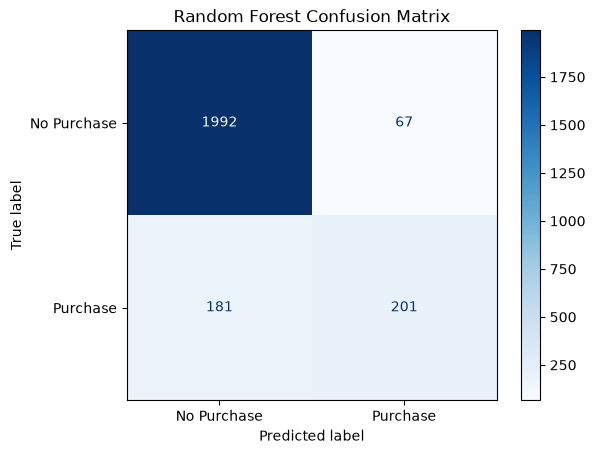

In [44]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Purchase", "Purchase"]
).plot(cmap="Blues")

plt.title("Random Forest Confusion Matrix")
plt.show()

In [45]:
#Tune the Random Forest
from sklearn.model_selection import GridSearchCV, StratifiedKFold

In [46]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [8, 12, 16, None],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__class_weight": [None, "balanced"]
}

In [47]:
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__class_weight': [None, 'balanced'], 'classifier__max_depth': [8, 12, ...], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_result

In [48]:
print("Best parameters:")
print(grid_search.best_params_)

print("Best cross-validation F1-score:")
print(grid_search.best_score_)

Best parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 200}
Best cross-validation F1-score:
0.6855187906257969


In [49]:
#  Evaluate the tuned model

best_model = grid_search.best_estimator_

tuned_pred = best_model.predict(X_test)
tuned_proba = best_model.predict_proba(X_test)[:, 1]

In [50]:
print(classification_report(
    y_test,
    tuned_pred,
    target_names=["No Purchase", "Purchase"],
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

 No Purchase     0.9475    0.9286    0.9379      2059
    Purchase     0.6525    0.7225    0.6857       382

    accuracy                         0.8964      2441
   macro avg     0.8000    0.8256    0.8118      2441
weighted avg     0.9013    0.8964    0.8985      2441



In [51]:
# Complete tuned-model evaluation
tuned_metrics = {
    "Accuracy": accuracy_score(y_test, tuned_pred),
    "Precision": precision_score(y_test, tuned_pred, zero_division=0),
    "Recall": recall_score(y_test, tuned_pred, zero_division=0),
    "F1-score": f1_score(y_test, tuned_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, tuned_proba),
    "PR-AUC": average_precision_score(y_test, tuned_proba),
}

print("Tuned model metrics:")
for metric, value in tuned_metrics.items():
    print(f"{metric}: {value:.4f}")


Tuned model metrics:
Accuracy: 0.8964
Precision: 0.6525
Recall: 0.7225
F1-score: 0.6857
ROC-AUC: 0.9249
PR-AUC: 0.7183


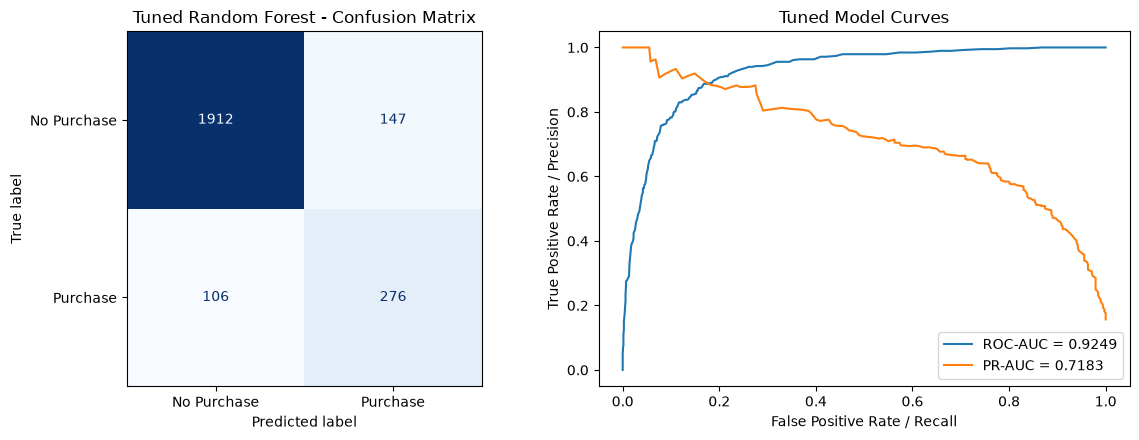

In [52]:
# Tuned-model confusion matrix and ROC/PR curves

tuned_cm = confusion_matrix(y_test, tuned_pred)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(
    confusion_matrix=tuned_cm,
    display_labels=["No Purchase", "Purchase"],
).plot(cmap="Blues", values_format="d", ax=axes[0], colorbar=False)
axes[0].set_title("Tuned Random Forest - Confusion Matrix")
axes[0].grid(False)

fpr, tpr, _ = roc_curve(y_test, tuned_proba)
precision, recall, _ = precision_recall_curve(y_test, tuned_proba)
axes[1].plot(fpr, tpr, label=f"ROC-AUC = {tuned_metrics['ROC-AUC']:.4f}")
axes[1].plot(recall, precision, label=f"PR-AUC = {tuned_metrics['PR-AUC']:.4f}")
axes[1].set_xlabel("False Positive Rate / Recall")
axes[1].set_ylabel("True Positive Rate / Precision")
axes[1].set_title("Tuned Model Curves")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "tuned_model_evaluation.png"), dpi=200)
plt.show()


Best threshold from out-of-fold predictions: 0.52
Accuracy: 0.8959
Precision: 0.6546
Recall: 0.7094
F1-score: 0.6809
ROC-AUC: 0.9249
PR-AUC: 0.7183


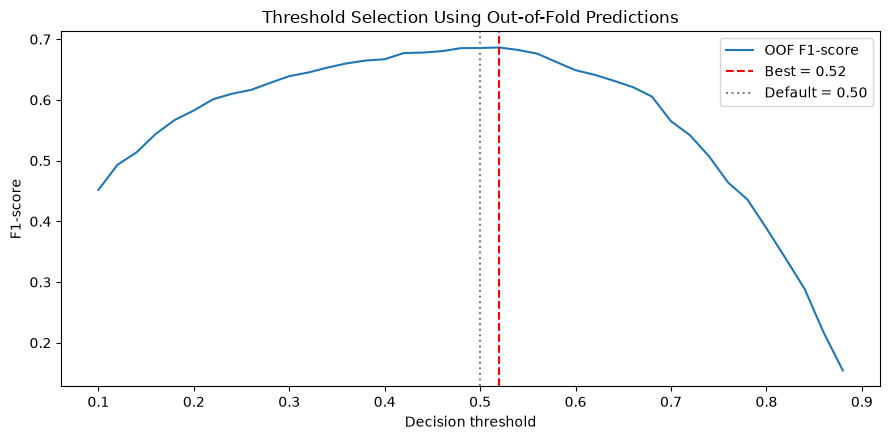

In [53]:
# Find a decision threshold using out-of-fold training predictions

oof_proba = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

thresholds = np.arange(0.10, 0.90, 0.02)
oof_f1_scores = [
    f1_score(y_train, (oof_proba >= threshold).astype(int), zero_division=0)
    for threshold in thresholds
]
best_threshold = float(thresholds[int(np.argmax(oof_f1_scores))])

optimized_pred = (tuned_proba >= best_threshold).astype(int)
optimized_metrics = {
    "Accuracy": accuracy_score(y_test, optimized_pred),
    "Precision": precision_score(y_test, optimized_pred, zero_division=0),
    "Recall": recall_score(y_test, optimized_pred, zero_division=0),
    "F1-score": f1_score(y_test, optimized_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, tuned_proba),
    "PR-AUC": average_precision_score(y_test, tuned_proba),
}

print(f"Best threshold from out-of-fold predictions: {best_threshold:.2f}")
for metric, value in optimized_metrics.items():
    print(f"{metric}: {value:.4f}")

plt.figure(figsize=(9, 4.5))
plt.plot(thresholds, oof_f1_scores, label="OOF F1-score")
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Best = {best_threshold:.2f}")
plt.axvline(0.50, color="gray", linestyle=":", label="Default = 0.50")
plt.xlabel("Decision threshold")
plt.ylabel("F1-score")
plt.title("Threshold Selection Using Out-of-Fold Predictions")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "threshold_analysis.png"), dpi=200)
plt.show()


In [54]:
# Feature importance analysis

classifier = best_model.named_steps["classifier"]
transformed_names = best_model.named_steps["preprocessor"].get_feature_names_out()
mdi_importance = pd.DataFrame({
    "feature": [name.split("__", 1)[-1] for name in transformed_names],
    "importance": classifier.feature_importances_,
}).sort_values("importance", ascending=False)

print("Top features by mean decrease in impurity:")
display(mdi_importance.head(10))

permutation = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
permutation_importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": permutation.importances_mean,
    "importance_std": permutation.importances_std,
}).sort_values("importance_mean", ascending=False)

print("Top features by permutation importance:")
display(permutation_importance_df.head(10))


Top features by mean decrease in impurity:


,feature,importance
8,PageValues,0.329637
7,ExitRates,0.094083
5,ProductRelated_Duration,0.083718
4,ProductRelated,0.066066
6,BounceRates,0.050876
1,Administrative_Duration,0.048349
0,Administrative,0.041385
17,Month_Nov,0.025510
3,Informational_Duration,0.021660
2,Informational,0.015774


Top features by permutation importance:


,feature,importance_mean,importance_std
8,PageValues,0.460601,0.017741
7,ExitRates,0.042822,0.016267
10,Month,0.019418,0.006697
5,ProductRelated_Duration,0.012571,0.003319
4,ProductRelated,0.010857,0.004238
6,BounceRates,0.010471,0.006108
15,TrafficType,0.005778,0.003248
0,Administrative,0.005447,0.002804
9,SpecialDay,0.004599,0.001234
1,Administrative_Duration,0.004080,0.004781


In [55]:
# Export metrics and predictions

summary = {
    "best_parameters": grid_search.best_params_,
    "best_cv_f1": float(grid_search.best_score_),
    "test_metrics_threshold_0.50": {key: float(value) for key, value in tuned_metrics.items()},
    "best_threshold": best_threshold,
    "test_metrics_best_threshold": {key: float(value) for key, value in optimized_metrics.items()},
    "confusion_matrix_threshold_0.50": tuned_cm.tolist(),
}

with open(os.path.join(OUTPUT_DIR, "random_forest_notebook_results.json"), "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=2)

pd.DataFrame({
    "y_true": y_test.to_numpy(),
    "purchase_probability": tuned_proba,
    "prediction_threshold_0.50": tuned_pred,
    "prediction_optimized_threshold": optimized_pred,
}).to_csv(os.path.join(OUTPUT_DIR, "random_forest_notebook_predictions.csv"), index=False)

print("Saved metrics and predictions to the results folder.")


Saved metrics and predictions to the results folder.
